In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [3]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [32]:
def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [76]:
import math
def weighted_avg_and_std(values, weights):
    """
    Return the weighted average and standard deviation.

    values, weights -- Numpy ndarrays with the same shape.
    """
    average = np.average(values, weights=weights)
    # Fast and numerically precise:
    variance = np.average((values-average)**2, weights=weights)
    return (average, math.sqrt(variance))

In [58]:
observables = ['evid','xsec','pt','n','parton','nch','pt1','q1','eta1','phi1','pid1','parent1','pt2','q2','eta2','phi2','pid2','parent2',\
              'dr','m','nparents1','nparents2']

In [78]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_nodecay_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_nodecay_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_nodecay_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_nodecay_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_nodecay_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_nodecay_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_nodecay_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_nodecay_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_nodecay_50pthat1000_rc_truth.txt']

In [79]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [80]:
df = applyCut(df, 'pt>20')
df.eval('b_ch = q1*q2', inplace=True)
df.eval('e = pt1+pt2', inplace=True)
df.eval('t = 1/(2*pt1/e*pt2*(1-cos(dr)))', inplace=True)

In [62]:
print('number of jets with q1 == -1:', df[df.q1==-1].shape[0])
print('number of jets with q1 == +1:', df[df.q1==1].shape[0])

number of jets with q1 == -1: 510175
number of jets with q1 == +1: 756502


In [9]:
np.unique(np.concatenate([np.asarray(df['pid1']),np.asarray(df['pid2'])]))

array([-9000211,  -100323,  -100321,  -100213,  -100211,   -30323,
         -30213,   -23312,   -23222,   -23112,   -22212,   -20523,
         -20433,   -20413,   -20325,   -20323,   -20213,   -15312,
         -14322,   -14122,   -13312,   -13222,   -13112,   -12212,
         -10523,   -10521,   -10433,   -10431,   -10413,   -10411,
         -10325,   -10323,   -10321,   -10215,   -10213,   -10211,
          -5334,    -5332,    -5314,    -5312,    -5224,    -5222,
          -5132,    -5114,    -5112,    -4324,    -4322,    -4232,
          -4224,    -4222,    -4214,    -4212,    -4122,    -3334,
          -3314,    -3312,    -3224,    -3222,    -3114,    -3112,
          -2224,    -2214,    -2212,    -1114,     -525,     -523,
           -521,     -435,     -433,     -431,     -415,     -413,
           -411,     -327,     -325,     -323,     -321,     -217,
           -215,     -213,     -211,       11,      211,      213,
            215,      217,      321,      323,      325,      

In [31]:
np.unique(np.concatenate([np.asarray(df['parent1']),np.asarray(df['parent2'])]))

array([22, 81])

In [32]:
np.unique(np.concatenate([np.asarray(df['nparents1']),np.asarray(df['nparents2'])]))

array([1])

In [81]:
df = applyCut(df, 'abs(parent1)>15 and abs(parent2)>15 and abs(pid1)>15 and abs(pid2)>15 and parent1!=22')

In [16]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [17]:
nodecay_rc_array = []
nodecay_rc_err_array = []
for i in range(0, len(df_array)):
    nodecay_rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    nodecay_rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [15]:
df_array = []
for i in range(1, 6):
    df_array.append(df[(df.n>2*i) & (df.n<2*(i+1))])

In [16]:
nodecay_rc_array = []
nodecay_rc_err_array = []
for i in range(0, len(df_array)):
    nodecay_rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    nodecay_rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [64]:
y_nodecay, yerr_nodecay = calc_hist(df['n'], bins=np.arange(2,16), weights=df['w'], density=True)[:2]

In [82]:
print(weighted_avg_and_std(df['n'], weights=df['w']))

(4.881732501713149, 1.5253974913650696)


In [65]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_50pthat1000_rc_truth.txt']

In [66]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [67]:
df = applyCut(df, 'pt>20')
df.eval('b_ch = q1*q2', inplace=True)

In [23]:
print('number of jets with q1 == -1:', df[df.q1==-1].shape[0])
print('number of jets with q1 == +1:', df[df.q1==1].shape[0])

number of jets with q1 == -1: 693358
number of jets with q1 == +1: 930252


In [24]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [23]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [25]:
df_array = []
for i in range(1, 6):
    df_array.append(df[(df.n>2*i) & (df.n<2*(i+1))])

In [26]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [68]:
y, yerr = calc_hist(df['n'], bins=np.arange(2,16), weights=df['w'], density=True)[:2]

In [77]:
print(weighted_avg_and_std(df['n'], weights=df['w']))

(7.361717256127496, 2.37913671590958)


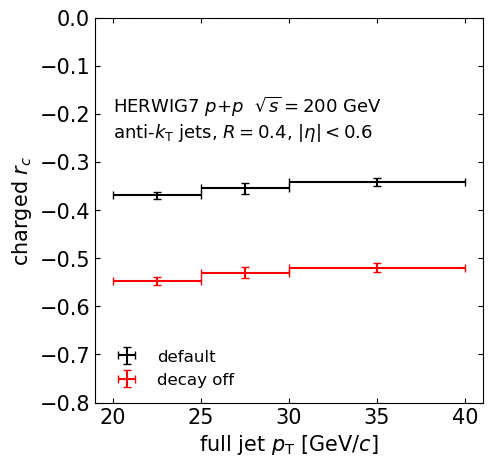

In [25]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_array, xerr=[2.5, 2.5, 5], yerr=rc_err_array, capsize=3, ls='none', label='default', color='k')
plt.errorbar([22.5, 27.5, 35], nodecay_rc_array, xerr=[2.5, 2.5, 5], yerr=nodecay_rc_err_array, capsize=3, ls='none', label='decay off', color='r')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(20,-0.25,'HERWIG7 $p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$', fontsize=15)
plt.ylim(-0.8,0)
plt.legend(fontsize=12, loc='lower left', frameon=False)
plt.xticks(np.arange(20, 45, 5), fontsize=15)
plt.yticks(fontsize=15)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

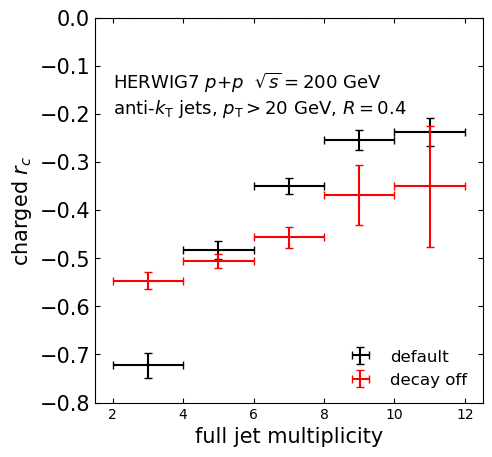

In [30]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(np.arange(3, 13, 2), rc_array, xerr=1, yerr=rc_err_array, capsize=3, ls='none', label='default', color='k')
plt.errorbar(np.arange(3, 13, 2), nodecay_rc_array, xerr=1, yerr=nodecay_rc_err_array, capsize=3, ls='none', label='decay off', color='r')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'full jet multiplicity', fontsize=15)
plt.text(2,-0.2,'HERWIG7 $p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $p_{\mathrm{T}}>20$ GeV, $R=0.4$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$', fontsize=15)
plt.ylim(-0.8,0)
plt.legend(fontsize=12, loc='lower right', frameon=False)
#plt.xticks(np.arange(20, 45, 5), fontsize=15)
plt.yticks(fontsize=15)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

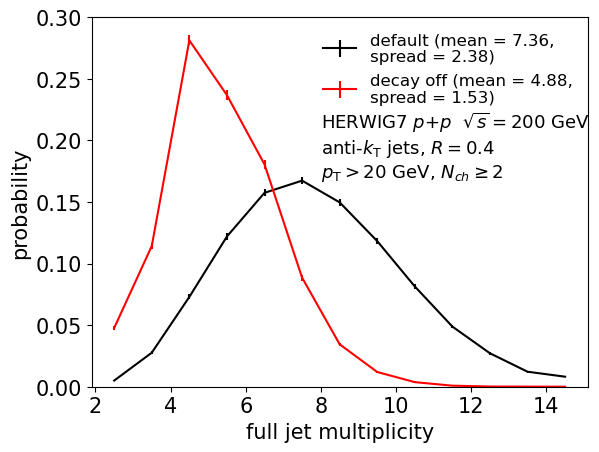

In [94]:
plt.errorbar(np.arange(2.5, 15.5), y, yerr=yerr, color='k', label='default (mean = 7.36,\nspread = 2.38)')
plt.errorbar(np.arange(2.5, 15.5), y_nodecay, yerr=yerr_nodecay, color='r', label='decay off (mean = 4.88,\nspread = 1.53)')
plt.xlabel(r'full jet multiplicity', fontsize=15)
plt.ylabel('probability', fontsize=15)
plt.text(8, 0.17,'HERWIG7 $p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$\n$p_{\mathrm{T}}>20$ GeV, $N_{ch}\geq2$', fontsize=13)
plt.ylim(0,0.3)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.legend(fontsize=12, loc='upper right', frameon=False)

In [33]:
observables = ['evid','xsec','pt','n','parton','pt1','q1','eta1','phi1','pid1','parent1','pt2','q2','eta2','phi2','pid2','parent2',\
              'dr','m','nparents1','nparents2']

In [34]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_nodecay_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_nodecay_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_nodecay_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_nodecay_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_nodecay_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_nodecay_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_nodecay_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_nodecay_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_original_def_nodecay_50pthat1000_rc_truth.txt']

In [35]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [36]:
df = applyCut(df, 'pt>20')
df.eval('b_ch = q1*q2', inplace=True)

In [37]:
print('number of jets with q1 == -1:', df[df.q1==-1].shape[0])
print('number of jets with q1 == +1:', df[df.q1==1].shape[0])

number of jets with q1 == -1: 182319
number of jets with q1 == +1: 231905


In [38]:
np.unique(np.concatenate([np.asarray(df['pid1']),np.asarray(df['pid2'])]))

array([-9000211,  -100323,  -100321,  -100213,  -100211,   -30323,
         -30213,   -23312,   -23222,   -23112,   -22212,   -20523,
         -20433,   -20413,   -20325,   -20323,   -20213,   -15312,
         -14322,   -14122,   -13312,   -13222,   -13112,   -12212,
         -10523,   -10521,   -10433,   -10431,   -10413,   -10411,
         -10325,   -10323,   -10321,   -10215,   -10213,   -10211,
          -5332,    -5314,    -5312,    -5224,    -5222,    -5132,
          -5114,    -5112,    -4322,    -4232,    -4224,    -4222,
          -4214,    -4212,    -4122,    -3334,    -3314,    -3312,
          -3224,    -3222,    -3114,    -3112,    -2224,    -2214,
          -2212,    -1114,     -525,     -523,     -521,     -435,
           -433,     -431,     -415,     -413,     -411,     -327,
           -325,     -323,     -321,     -217,     -215,     -213,
           -211,       11,      211,      213,      215,      217,
            321,      323,      325,      327,      411,      

In [39]:
df = applyCut(df, 'abs(parent1)>15 and abs(parent2)>15 and abs(pid1)>15 and abs(pid2)>15')

In [40]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [41]:
nodecay_rc_array = []
nodecay_rc_err_array = []
for i in range(0, len(df_array)):
    nodecay_rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    nodecay_rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [42]:
observables = ['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale']

In [45]:
files = ['/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_11pthat15_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_15pthat20_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_20pthat25_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_25pthat30_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_30pthat35_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_35pthat40_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_40pthat45_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_45pthat50_rc.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/rc/herwig_50pthat_rc.txt']

In [46]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [47]:
df = applyCut(df, 'pt>20 and b!=0 and b!=-9')

In [48]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [49]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b')[1])

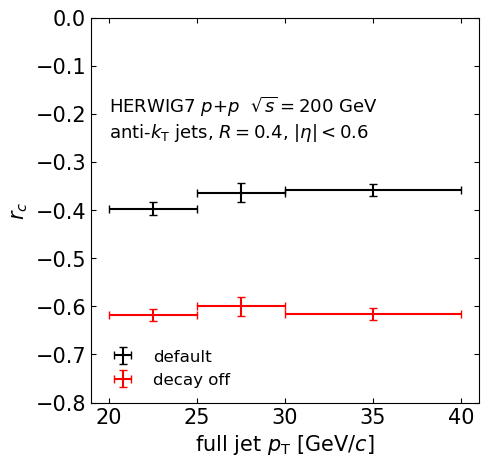

In [50]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_array, xerr=[2.5, 2.5, 5], yerr=rc_err_array, capsize=3, ls='none', label='default', color='k')
plt.errorbar([22.5, 27.5, 35], nodecay_rc_array, xerr=[2.5, 2.5, 5], yerr=nodecay_rc_err_array, capsize=3, ls='none', label='decay off', color='r')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(20,-0.25,'HERWIG7 $p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$', fontsize=15)
plt.ylim(-0.8,0)
plt.legend(fontsize=12, loc='lower left', frameon=False)
plt.xticks(np.arange(20, 45, 5), fontsize=15)
plt.yticks(fontsize=15)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

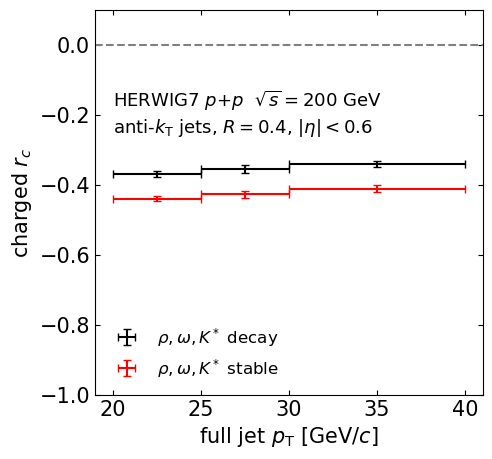

In [19]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_array, xerr=[2.5, 2.5, 5], yerr=rc_err_array, capsize=3, ls='none', label=r'$\rho,\omega,K^*$ decay', color='k')
plt.errorbar([22.5, 27.5, 35], stable_resonance_rc_array, xerr=[2.5, 2.5, 5], yerr=stable_resonance_rc_err_array, capsize=3, ls='none', label=r'$\rho,\omega,K^*$ stable', color='r')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(20,-0.25,'HERWIG7 $p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$', fontsize=15)
plt.ylim(-1,0.1)
plt.legend(fontsize=12, loc='lower left', frameon=False)
plt.xticks(np.arange(20, 45, 5), fontsize=15)
plt.yticks(fontsize=15)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

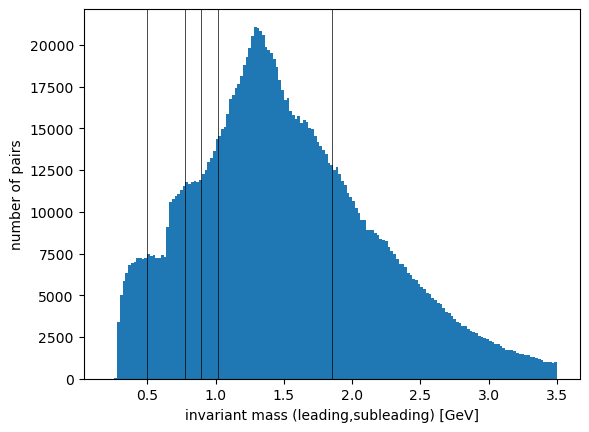

In [10]:
plt.hist(df['m'], bins=np.arange(0.2, 3.52, 0.02))
plt.xlabel('invariant mass (leading,subleading) [GeV]')
plt.ylabel('number of pairs')
plt.axvline(0.498, color='k', linewidth=0.5) # K0L,K0S? pid==130,310
plt.axvline(0.775, color='k', linewidth=0.5) # rho, found
plt.axvline(0.892, color='k', linewidth=0.5) # K*, found
plt.axvline(1.019, color='k', linewidth=0.5) # phi, pid==333
plt.axvline(1.850, color='k', linewidth=0.5) # ???

In [11]:
print(sum(df[df.parent1!=81]['w'])/sum(df['w']))
print(sum(df[df.parent2!=81]['w'])/sum(df['w']))

0.4110099686518049
0.4625926155680322


In [12]:
unique_parent1_array = np.unique(df['parent1'])
unique_parent2_array = np.unique(df['parent2'])

In [13]:
print(unique_parent2_array)

[-9000211  -100323  -100321  -100313  -100311  -100213  -100211   -33122
   -30323   -30313   -30213   -23322   -23312   -23222   -23212   -23122
   -23112   -22212   -22112   -20533   -20523   -20513   -20433   -20423
   -20413   -20325   -20323   -20315   -20313   -20213   -15322   -15122
   -14322   -14312   -14122   -13322   -13312   -13222   -13212   -13122
   -13112   -12212   -12112   -10533   -10531   -10523   -10521   -10513
   -10511   -10433   -10423   -10421   -10413   -10411   -10325   -10323
   -10321   -10315   -10313   -10311   -10215   -10213   -10211    -5332
    -5324    -5314    -5232    -5224    -5222    -5132    -5122    -5114
    -5112    -4332    -4324    -4314    -4232    -4224    -4222    -4132
    -4122    -4114    -4112    -3324    -3314    -3224    -3214    -3124
    -3114    -1114     -535     -531     -525     -521     -515     -511
     -435     -431     -425     -415     -413     -411     -327     -325
     -323     -317     -315     -313     -217     -

In [28]:
for parent in unique_parent2_array:
    if parent in stable_pid:
        print(parent)

113
213
323


In [16]:
pid_array = []
prob_array = []
df_211 = applyCut(df, 'pid2==211')
print('subleading track pid: 211')
for unique_parent2 in unique_parent2_array:
    prob = sum(df_211[df_211.parent2==unique_parent2]['w'])/sum(df_211['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2, ', probability:', prob)
    pid_array.append(str(unique_parent2))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: 211
subleading track parent pid: -20213 , probability: 0.012263720141088516
subleading track parent pid: -1114 , probability: 0.01257516032021563
subleading track parent pid: 81 , probability: 0.431205682805277
subleading track parent pid: 115 , probability: 0.01984121836310347
subleading track parent pid: 215 , probability: 0.034432779579010614
subleading track parent pid: 225 , probability: 0.04249257713960638
subleading track parent pid: 325 , probability: 0.011999297570444609
subleading track parent pid: 331 , probability: 0.010845719439775834
subleading track parent pid: 10213 , probability: 0.042425143075563033
subleading track parent pid: 10215 , probability: 0.010178408770177113
subleading track parent pid: 10223 , probability: 0.016402616750446932
subleading track parent pid: 10321 , probability: 0.010029425438279846
subleading track parent pid: 20113 , probability: 0.030709197049480205
subleading track parent pid: 20213 , probability: 0.05342480553110087

In [17]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [18]:
stable_resonance_rc_array = []
stable_resonance_rc_err_array = []
for i in range(0, len(df_array)):
    stable_resonance_rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    stable_resonance_rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

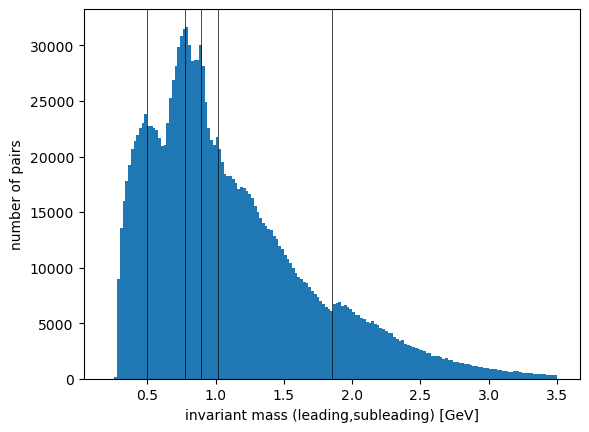

In [11]:
plt.hist(df['m'], bins=np.arange(0.2, 3.52, 0.02))
plt.xlabel('invariant mass (leading,subleading) [GeV]')
plt.ylabel('number of pairs')
plt.axvline(0.498, color='k', linewidth=0.5) # K0L,K0S? pid==130,310
plt.axvline(0.775, color='k', linewidth=0.5) # rho, found
plt.axvline(0.892, color='k', linewidth=0.5) # K*, found
plt.axvline(1.019, color='k', linewidth=0.5) # phi, pid==333
plt.axvline(1.850, color='k', linewidth=0.5) # ???

In [17]:
stable_pid = [111, 211, 221, 321, 310, 130, 3122, 3212, 3122, 3222, 3312, 3322, 3334]
# pi0, pi+, eta, K+, Kshort, Klong, Lambda0, Sigma0, Sigma-, Sigma+, Xi-, Xi0, Omega-

In [18]:
bad_jet_index = []
for i in range(0, df.shape[0]):
    if ((abs(df.iloc[i]['parent1']) in stable_pid) or (abs(df.iloc[i]['parent2']) in stable_pid)):
        bad_jet_index.append(i)

In [19]:
sum(df.iloc[bad_jet_index]['w'])/sum(df['w'])

0.0035786753872541115

In [9]:
print(sum(df[df.parent1!=81]['w'])/sum(df['w']))
print(sum(df[df.parent2!=81]['w'])/sum(df['w']))

0.6723120236079407
0.7356540215306834


In [10]:
unique_parent1_array = np.unique(df['parent1'])
unique_parent2_array = np.unique(df['parent2'])

In [11]:
print(unique_parent2_array)

[-9000211  -100323  -100321  -100313  -100311  -100213  -100211   -33122
   -30323   -30313   -30213   -23322   -23312   -23222   -23212   -23122
   -23112   -22212   -22112   -20533   -20523   -20513   -20433   -20423
   -20413   -20325   -20323   -20315   -20313   -20213   -14122   -13322
   -13312   -13222   -13212   -13122   -13112   -12212   -12112   -10533
   -10531   -10523   -10521   -10513   -10511   -10433   -10423   -10421
   -10413   -10411   -10325   -10323   -10321   -10315   -10313   -10311
   -10215   -10213   -10211    -5332    -5232    -5224    -5222    -5132
    -5122    -5114    -5112    -4332    -4314    -4232    -4224    -4222
    -4132    -4122    -4114    -4112    -3334    -3324    -3314    -3312
    -3224    -3222    -3214    -3124    -3122    -3114    -3112    -2224
    -2214    -2114    -1114     -535     -531     -525     -521     -515
     -511     -435     -431     -425     -421     -415     -413     -411
     -327     -325     -323     -317     -315     -

In [ ]:
# old

# When leading and subleading are a charged kaon and pion pair, and have the same parent, what is this parent?

In [15]:
df.eval('pid_product=pid1*pid2', inplace=True)
df_kpi = applyCut(df, 'pid_product == 67731 or pid_product == -67731') # leading and subleading are K and pi
df_kpi_likely_decay = applyCut(df_kpi, 'parent1 == parent2') # leading and subleading have the same parent PID (not necessarily the same parent)
parent_candidate_array = np.unique(df_kpi_likely_decay['parent1']) # all possible parent types
for parent_candidate in parent_candidate_array:
    prob = sum(df_kpi_likely_decay[df_kpi_likely_decay.parent1==parent_candidate]['w'])/sum(df_kpi['w'])
    if (prob > 0.01):
        print('parent pid:', parent_candidate, ', probability:', prob)

parent pid: -313 , probability: 0.028520431257162644
parent pid: 81 , probability: 0.11040768860308459
parent pid: 313 , probability: 0.04617794599028352


# List parent PIDs and probabilities

In [15]:
pid_array = []
prob_array = []
df_2212 = applyCut(df, 'pid1==2212')
prob_tot = 0
print('leading track pid: 2212')
for unique_parent1 in unique_parent1_array:
    prob = sum(df_2212[df_2212.parent1==unique_parent1]['w'])/sum(df_2212['w'])
    if (prob > 0.01):
        print('leading track parent pid:', unique_parent1, ', probability:', prob)
    pid_array.append(str(unique_parent1))
    #prob_array.append([prob])
    prob_array.append(prob)
    prob_tot += prob

leading track pid: 2212
leading track parent pid: 81 , probability: 0.559751425390541
leading track parent pid: 2114 , probability: 0.049923654916090764
leading track parent pid: 2214 , probability: 0.09239655502704253
leading track parent pid: 2224 , probability: 0.15552584146077492
leading track parent pid: 12112 , probability: 0.04055906251942101
leading track parent pid: 12212 , probability: 0.024128817225802925
leading track parent pid: 22112 , probability: 0.02228757628069101
leading track parent pid: 22212 , probability: 0.03383639451456048


In [13]:
pid_array = []
prob_array = []
df_211 = applyCut(df, 'pid2==211')
prob_tot = 0
print('subleading track pid: 211')
for unique_parent2 in unique_parent2_array:
    prob = sum(df_211[df_211.parent2==unique_parent2]['w'])/sum(df_211['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2, ', probability:', prob)
    pid_array.append(str(unique_parent2))
    #prob_array.append([prob])
    prob_array.append(prob)
    prob_tot += prob

subleading track pid: 211
subleading track parent pid: -313 , probability: 0.0206557798535436
subleading track parent pid: 81 , probability: 0.22435607461139923
subleading track parent pid: 113 , probability: 0.183560268778116
subleading track parent pid: 115 , probability: 0.01084456664610505
subleading track parent pid: 213 , probability: 0.2211412365243356
subleading track parent pid: 215 , probability: 0.013462895626399542
subleading track parent pid: 223 , probability: 0.0424641291959634
subleading track parent pid: 225 , probability: 0.026391471909037165
subleading track parent pid: 323 , probability: 0.038168096068946736
subleading track parent pid: 10213 , probability: 0.017164996839366
subleading track parent pid: 30213 , probability: 0.010399440085743996
subleading track parent pid: 9000211 , probability: 0.013446370732923218


In [20]:
prob_tot

0.999999999988409

In [ ]:
# 113: rho0, 213: rho+, 223: omega, 313: K*0, 323: K*+

In [14]:
pid_array = []
prob_array = []
df_n211 = applyCut(df, 'pid2==-211')
print('subleading track pid: -211')
for unique_parent2 in unique_parent2_array:
    prob = sum(df_n211[df_n211.parent2==unique_parent2]['w'])/sum(df_n211['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2, ', probability:', prob)
    pid_array.append(str(unique_parent2))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: -211
subleading track parent pid: -9000211 , probability: 0.013326621464679339
subleading track parent pid: -100213 , probability: 0.011164453475995132
subleading track parent pid: -10213 , probability: 0.017252980330152413
subleading track parent pid: -323 , probability: 0.02372351144076058
subleading track parent pid: -215 , probability: 0.012823019847555147
subleading track parent pid: -213 , probability: 0.2108875398134556
subleading track parent pid: 81 , probability: 0.20764123530897305
subleading track parent pid: 113 , probability: 0.19452639891457515
subleading track parent pid: 223 , probability: 0.04674159225067099
subleading track parent pid: 225 , probability: 0.02516306618303632
subleading track parent pid: 313 , probability: 0.03149127889199348
subleading track parent pid: 20113 , probability: 0.012993385634159194


In [35]:
pid_array = []
prob_array = []
df_321 = applyCut(df, 'pid2==321')
print('subleading track pid: 321')
for unique_parent2 in unique_parent2_array:
    prob = sum(df_321[df_321.parent2==unique_parent2]['w'])/sum(df_321['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2, ', probability:', prob)
    pid_array.append(str(unique_parent2))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: 321
subleading track parent pid: -421 , probability: 0.01681397212417925
subleading track parent pid: 81 , probability: 0.33359788336600593
subleading track parent pid: 225 , probability: 0.012584444462141669
subleading track parent pid: 313 , probability: 0.25494034117353775
subleading track parent pid: 315 , probability: 0.023389533442926744
subleading track parent pid: 323 , probability: 0.12601097938862335
subleading track parent pid: 325 , probability: 0.016134620597058266
subleading track parent pid: 333 , probability: 0.016000975705516434
subleading track parent pid: 335 , probability: 0.01095865953030371
subleading track parent pid: 10311 , probability: 0.02046751086880525
subleading track parent pid: 10313 , probability: 0.01491448887912953
subleading track parent pid: 10323 , probability: 0.01652577098515676
subleading track parent pid: 10325 , probability: 0.010308811890368487
subleading track parent pid: 9000111 , probability: 0.015641659457687616
subl

In [ ]:
# 313: K*0, 323: K*+, 333: phi, 421: D0

In [36]:
pid_array = []
prob_array = []
df_n321 = applyCut(df, 'pid2==-321')
print('subleading track pid: -321')
for unique_parent2 in unique_parent2_array:
    prob = sum(df_n321[df_n321.parent2==unique_parent2]['w'])/sum(df_n321['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2, ', probability:', prob)
    pid_array.append(str(unique_parent2))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: -321
subleading track parent pid: -9000211 , probability: 0.026577507469661255
subleading track parent pid: -30313 , probability: 0.010170842749137888
subleading track parent pid: -10323 , probability: 0.012891840226237709
subleading track parent pid: -10313 , probability: 0.01304707892128345
subleading track parent pid: -10311 , probability: 0.015339934534810461
subleading track parent pid: -327 , probability: 0.010258871391681766
subleading track parent pid: -325 , probability: 0.010115899339731473
subleading track parent pid: -323 , probability: 0.14509265333203655
subleading track parent pid: -315 , probability: 0.015553125961792461
subleading track parent pid: -313 , probability: 0.2332328816697761
subleading track parent pid: 81 , probability: 0.3362375423657097
subleading track parent pid: 333 , probability: 0.02182714476406211
subleading track parent pid: 421 , probability: 0.014730344746925486
subleading track parent pid: 9000111 , probability: 0.01731543

In [37]:
pid_array = []
prob_array = []
df_2212 = applyCut(df, 'pid2==2212')
print('subleading track pid: 2212')
for unique_parent2 in unique_parent2_array:
    prob = sum(df_2212[df_2212.parent2==unique_parent2]['w'])/sum(df_2212['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2, ', probability:', prob)
    pid_array.append(str(unique_parent2))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: 2212
subleading track parent pid: 81 , probability: 0.5594502650874604
subleading track parent pid: 2114 , probability: 0.04663741085249378
subleading track parent pid: 2214 , probability: 0.10523525588278757
subleading track parent pid: 2224 , probability: 0.17037640780779423
subleading track parent pid: 12112 , probability: 0.024049184350378013
subleading track parent pid: 12212 , probability: 0.022149965695722074
subleading track parent pid: 22112 , probability: 0.015692791302692927
subleading track parent pid: 22212 , probability: 0.042032604344246556


In [48]:
# 2114: Delta0, 2214: Delta+, 2224: Delta++

In [38]:
pid_array = []
prob_array = []
df_n2212 = applyCut(df, 'pid2==-2212')
print('subleading track pid: -2212')
for unique_parent2 in unique_parent2_array:
    prob = sum(df_n2212[df_n2212.parent2==unique_parent2]['w'])/sum(df_n2212['w'])
    if (prob > 0.01):
        print('subleading track parent pid:', unique_parent2, ', probability:', prob)
    pid_array.append(str(unique_parent2))
    #prob_array.append([prob])
    prob_array.append(prob)

subleading track pid: -2212
subleading track parent pid: -22212 , probability: 0.05321218504609494
subleading track parent pid: -22112 , probability: 0.0165275033788711
subleading track parent pid: -12212 , probability: 0.02542461046876639
subleading track parent pid: -12112 , probability: 0.03092395703445915
subleading track parent pid: -2224 , probability: 0.1512948312053162
subleading track parent pid: -2214 , probability: 0.09423004799330216
subleading track parent pid: -2114 , probability: 0.0622912023519806
subleading track parent pid: 81 , probability: 0.5482610345214006


# Assign specific codes to sign preserving decays

In [11]:
parent1_new = []
parent2_new = []
for i in range(0, df.shape[0]):
    parent1 = df.iloc[i]['parent1']
    parent2 = df.iloc[i]['parent2']
    pid1 = df.iloc[i]['pid1']
    pid2 = df.iloc[i]['pid2']
    if (parent1 == 81):
        parent1_new.append(-998)
    elif (abs(pid1) == 211 and abs(parent1) == 213): # sign preserving decay
        parent1_new.append(-997)
    elif (abs(pid1) == 321 and abs(parent1) == 323):
        parent1_new.append(-997)
    elif (abs(pid1) == 2212 and (abs(parent1) == 2214 or abs(parent1) == 2224)):
        parent1_new.append(-997)
    else:
        parent1_new.append(parent1)
    if (parent2 == 81):
        parent2_new.append(-998)
    elif (abs(pid2) == 211 and abs(parent2) == 213): # sign preserving decay
        parent2_new.append(-997)
    elif (abs(pid2) == 321 and abs(parent2) == 323):
        parent2_new.append(-997)
    elif (abs(pid2) == 2212 and (abs(parent2) == 2214 or abs(parent2) == 2224)):
        parent2_new.append(-997)
    else:
        parent2_new.append(parent2)

In [12]:
df['parent1_new'] = parent1_new
df['parent2_new'] = parent2_new

In [13]:
print(sum(df[(df.parent1_new!=-998) & (df.parent1_new!=-997)]['w'])/sum(df['w']))
print(sum(df[(df.parent2_new!=-998) & (df.parent2_new!=-997)]['w'])/sum(df['w']))

0.4715621371428063
0.5315414295115615


In [20]:
df.eval('b_ch = q1*q2', inplace=True)
df_signal = applyCut(df, '-999<=parent1_new<=-997 and -999<=parent2_new<=-997')
#df_nondecay = applyCut(df, 'parent1==-999 and parent2==-999')
#df_samesigndecay = applyCut(df, 'parent1==-997 and parent2==-997')
df_onedecay = applyCut(df, '(-999<=parent1_new<=-997 and (parent2_new<-999 or parent2_new>-997)) or\
                            (-999<=parent2_new<=-997 and (parent1_new<-999 or parent1_new>-997))')
df_twodecay = applyCut(df, '(parent1_new<-999 or parent1_new>-997) and (parent2_new<-999 or parent2_new>-997)')

In [15]:
df_array = [ df[(df.pt>20) & (df.pt<25)],\
            df[(df.pt>25) & (df.pt<30)],\
            df[(df.pt>30) & (df.pt<40)] ]

In [16]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [17]:
df_signal_array = [ df_signal[(df_signal.pt>20) & (df_signal.pt<25)],\
            df_signal[(df_signal.pt>25) & (df_signal.pt<30)],\
            df_signal[(df_signal.pt>30) & (df_signal.pt<40)] ]

In [18]:
signal_rc_array = []
signal_rc_err_array = []
for i in range(0, len(df_signal_array)):
    signal_rc_array.append(getRcAndErr(df_signal_array[i], 'b_ch')[0])
    signal_rc_err_array.append(getRcAndErr(df_signal_array[i], 'b_ch')[1])

In [21]:
df_onedecay_array = [ df_onedecay[(df_onedecay.pt>20) & (df_onedecay.pt<25)],\
            df_onedecay[(df_onedecay.pt>25) & (df_onedecay.pt<30)],\
            df_onedecay[(df_onedecay.pt>30) & (df_onedecay.pt<40)] ]

In [22]:
onedecay_rc_array = []
onedecay_rc_err_array = []
for i in range(0, len(df_onedecay_array)):
    onedecay_rc_array.append(getRcAndErr(df_onedecay_array[i], 'b_ch')[0])
    onedecay_rc_err_array.append(getRcAndErr(df_onedecay_array[i], 'b_ch')[1])

In [23]:
df_twodecay_array = [ df_twodecay[(df_twodecay.pt>20) & (df_twodecay.pt<25)],\
            df_twodecay[(df_twodecay.pt>25) & (df_twodecay.pt<30)],\
            df_twodecay[(df_twodecay.pt>30) & (df_twodecay.pt<40)] ]

In [24]:
twodecay_rc_array = []
twodecay_rc_err_array = []
for i in range(0, len(df_twodecay_array)):
    twodecay_rc_array.append(getRcAndErr(df_twodecay_array[i], 'b_ch')[0])
    twodecay_rc_err_array.append(getRcAndErr(df_twodecay_array[i], 'b_ch')[1])

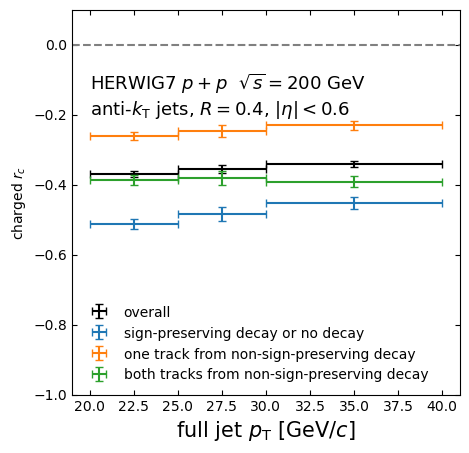

In [25]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_array, xerr=[2.5, 2.5, 5], yerr=rc_err_array, capsize=3, ls='none', label='overall', color='k')
plt.errorbar([22.5, 27.5, 35], signal_rc_array, xerr=[2.5, 2.5, 5], yerr=signal_rc_err_array, capsize=3, ls='none', label='sign-preserving decay or no decay')
plt.errorbar([22.5, 27.5, 35], onedecay_rc_array, xerr=[2.5, 2.5, 5], yerr=onedecay_rc_err_array, capsize=3, ls='none', label='one track from non-sign-preserving decay')
plt.errorbar([22.5, 27.5, 35], twodecay_rc_array, xerr=[2.5, 2.5, 5], yerr=twodecay_rc_err_array, capsize=3, ls='none', label='both tracks from non-sign-preserving decay')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
plt.xlabel(r'full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(20,-0.2,'HERWIG7 $p+p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$, $|\eta|<0.6$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$')
plt.ylim(-1,0.1)
plt.legend(fontsize=10, loc='lower left', frameon=False)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')